Hello guys. Turns out my previous method was wrong. Bruh.

let's try again.

So first, I'm sorting the water quality data based on the manual I found on their website, which contains the code for the different divisions of watermass of the Seto Inland Sea (SIS).

In [2]:
# Data sorting
# Install all required packages from requirements.txt
%pip install -r ../requirements.txt

^C
Note: you may need to restart the kernel to use updated packages.


In [4]:
import geopandas as gpd
import pandas as pd
import os

# Path to your Excel manual
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'

# Load the specific sheet from the Excel file
# We use header=3 because pandas is 0-indexed (row 4 is the 3rd index)
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)

# Rename the columns for easier use
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
})

# Display the first few rows to confirm it loaded correctly
print("Water Code Lookup Table:")
print(codes_df)

Water Code Lookup Table:
    watercode   watermass_name       division            details
0         100        Tokyo Bay              —                  —
1         200          Ise Bay              —                  —
2         301  Seto Inland Sea      Osaka Bay    North Osaka Bay
3         302  Seto Inland Sea      Osaka Bay    South Osaka Bay
4         303  Seto Inland Sea    Kii Channel   East Kii Channel
5         304  Seto Inland Sea    Kii Channel   West Kii Channel
6         305  Seto Inland Sea    Harima Nada  North Harima Nada
7         306  Seto Inland Sea    Harima Nada  South Harima Nada
8         307  Seto Inland Sea     Bisan Seto    East Bisan Seto
9         308  Seto Inland Sea     Bisan Seto    West Bisan Seto
10        309  Seto Inland Sea     Bingo Nada         Bingo Nada
11        310  Seto Inland Sea    Hiuchi Nada        Hiuchi Nada
12        311  Seto Inland Sea       Aki Nada           Aki Nada
13        312  Seto Inland Sea  Hiroshima Bay      Hiroshima Bay


In [5]:
# Path to the folder containing your yearly data folders
base_data_path = '../data/raw/environmental_data'

# List to hold each dataset's GeoDataFrame
gdfs = []

print(f"\nSearching for shapefiles in: {os.path.abspath(base_data_path)}")

# Use os.walk() to go through all subdirectories
for dirpath, dirnames, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames:
        folder_name = os.path.basename(dirpath)
        
        try:
            year = int(folder_name.split('_')[0])
        except (ValueError, IndexError):
            print(f"Could not parse year from '{folder_name}'. Skipping.")
            continue
            
        shp_filepath = os.path.join(dirpath, 'output.shp')
        gdf_temp = gpd.read_file(shp_filepath)
        gdf_temp['year'] = year
        
        gdfs.append(gdf_temp)
        print(f"Loaded data for year: {year}")

# Combine all data into a single master GeoDataFrame
if gdfs:
    all_points_gdf = pd.concat(gdfs, ignore_index=True)
    print(f"\n✅ All shapefiles combined successfully! Total points: {len(all_points_gdf)}")
else:
    print("\n❌ No shapefiles were found.")

# Show columns of the first GeoDataFrame in the list
if gdfs:
    print(gdfs[0].columns)
else:
    print("No GeoDataFrames loaded.")


Searching for shapefiles in: c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\data\raw\environmental_data
Loaded data for year: 1981
Loaded data for year: 1981
Loaded data for year: 1982
Loaded data for year: 1982
Loaded data for year: 1983
Loaded data for year: 1983
Loaded data for year: 1984
Loaded data for year: 1984
Loaded data for year: 1985
Loaded data for year: 1985
Loaded data for year: 1986
Loaded data for year: 1986
Loaded data for year: 1987
Loaded data for year: 1987
Loaded data for year: 1988
Loaded data for year: 1988
Loaded data for year: 1989
Loaded data for year: 1989
Loaded data for year: 1990
Loaded data for year: 1990
Loaded data for year: 1991
Loaded data for year: 1991
Loaded data for year: 1992
Loaded data for year: 1992
Loaded data for year: 1993
Loaded data for year: 1993
Loaded data for year: 1994
Loaded data for year: 1994
Loaded data for year: 1995
Loaded data for year: 1995
Loaded data for year: 1996
Loaded data

In [7]:
# Convert both 'watercode' columns to the integer type
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int)
codes_df['watercode'] = codes_df['watercode'].astype(int)

# Check the data types for your first DataFrame
print("Data types for all_points_gdf:")
print(all_points_gdf['watercode'].dtypes)

# Check the data types for your second DataFrame
print("\nData types for codes_df:")
print(codes_df['watercode'].dtypes)

# Perform a 'left' merge. This keeps all your data points and adds the
# 'name' column where the 'watercode' matches.
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left')
print("\n✅ Merge complete!")
print(f"Total points after merge: {len(merged_gdf)}")

Data types for all_points_gdf:
int64

Data types for codes_df:
int64

✅ Merge complete!
Total points after merge: 41346


In [8]:
# Check the first few rows. Note the new 'name' column at the end.
print("\nPreview of merged data:")
# print(merged_gdf.head())
print(merged_gdf.columns)

# Get a count of data points for each named water mass across all years
print("\nTotal data points per water mass:")
print(merged_gdf['watermass_name'].value_counts())

# Get a statistical summary of all numeric columns
print("\nStatistical summary of numeric columns:")
print(merged_gdf.describe())

# Bonus: Check if any watercodes in your data did not have a match in the manual
unmatched_codes = merged_gdf[merged_gdf['watermass_name'].isnull()]['watercode'].unique()
if len(unmatched_codes) > 0:
    print(f"\nWarning: The following watercodes in your data had no match: {unmatched_codes}")
else:
    print("\n✅ All watercodes were successfully matched to a name.")


Preview of merged data:
Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details'],
      dtype='object')

Total data points per water mass:
watermass_name
Seto Inland Sea    41346
Name: count, dtype: int64

Statistical summary of numeric columns:
          watercode         nendo                   survey_ym    surveyyear  \
count  

Nice. Now it's time for the analysis. Let's do the main one first, Dissolved Oxygen.

In [10]:
# Making a new dataframe for dissolved oxygen analysis
do_data = merged_gdf[['year', 'division', 'do_', 'locationna']]
print(do_data.head())

   year   division   do_ locationna
0  1981  Osaka Bay  12.4      兵庫県11
1  1981  Osaka Bay   3.2      兵庫県11
2  1981  Osaka Bay   8.7      兵庫県11
3  1981  Osaka Bay   4.4      兵庫県11
4  1981  Osaka Bay   3.9      兵庫県11


In [11]:
print("Preview of unique sampling periods and sampling time")

# Years to filter
years_of_interest = [2022, 2017, 2012, 2007, 2002, 1997, 1992, 1987, 1981]

# Dictionary to store yearly Osaka Bay dataframes
osaka_bay_yearly = {}

for yr in years_of_interest:
    df_year = merged_gdf[(merged_gdf['division'] == 'Osaka Bay') & (merged_gdf['year'] == yr)]
    osaka_bay_yearly[yr] = df_year
    print(f"\nYear: {yr}")

    unique_survey_period = df_year['survey_ym'].unique()
    print(f"  survey_ym({yr}): {len(unique_survey_period)} unique values")
    print(f"    Values: {unique_survey_period}")

    unique_sampling_month = df_year['surveymont'].unique()
    print(f"  surveymont({yr}): {len(unique_sampling_month)} unique values")
    print(f"    Values: {unique_sampling_month}")

    unique_sampling_location = df_year['locationna'].unique()
    print(f"  locationna({yr}): {len(unique_sampling_location)} unique values")
    print(f"    Values: {unique_sampling_location}")
# Example: Access 2022 Osaka Bay data with osaka_bay_yearly[2022]

Preview of unique sampling periods and sampling time

Year: 2022
  survey_ym(2022): 4 unique values
    Values: <DatetimeArray>
['2022-03-01 00:00:00', '2022-06-01 00:00:00', '2022-09-01 00:00:00',
 '2022-12-01 00:00:00']
Length: 4, dtype: datetime64[ms]
  surveymont(2022): 4 unique values
    Values: [ 5  7 10  1]
  locationna(2022): 10 unique values
    Values: ['大阪府2' '大阪府5' '大阪府25' '大阪府37' '大阪府44' '大阪府50' '大阪府58' '兵庫県11' '兵庫県23'
 '兵庫県48']

Year: 2017
  survey_ym(2017): 4 unique values
    Values: <DatetimeArray>
['2017-03-01 00:00:00', '2017-06-01 00:00:00', '2017-09-01 00:00:00',
 '2017-12-01 00:00:00']
Length: 4, dtype: datetime64[ms]
  surveymont(2017): 4 unique values
    Values: [ 5  7 10  1]
  locationna(2017): 10 unique values
    Values: ['大阪府2' '大阪府5' '大阪府37' '大阪府44' '大阪府50' '大阪府58' '大阪府25' '兵庫県23' '兵庫県11'
 '兵庫県48']

Year: 2012
  survey_ym(2012): 4 unique values
    Values: <DatetimeArray>
['2012-03-01 00:00:00', '2012-06-01 00:00:00', '2012-12-01 00:00:00',
 '2012-09-01 0

In [ ]:
# Find out how many number of measurement instances recorded in every month
# Count the number of measurement instances for each month in the 'surveymont' column
month_counts = merged_gdf['surveymont'].value_counts().sort_index()
print("Number of measurement instances per month:")
print(month_counts)

Number of measurement instances per month:
surveymont
1      9990
2       464
3         6
5     10168
6        30
7      9862
8       622
10    10080
11      114
12       10
Name: count, dtype: int64


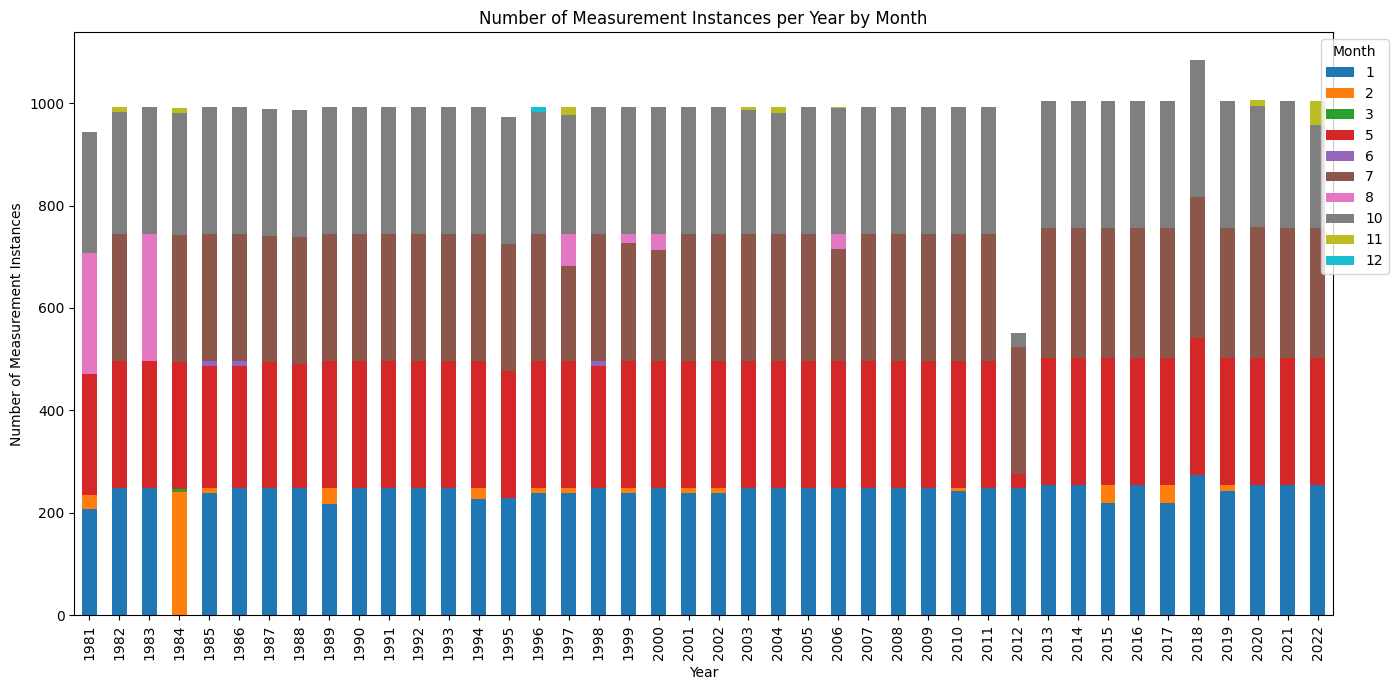

In [15]:
import matplotlib.pyplot as plt

# Group by year and month, then count the number of measurements
counts = merged_gdf.groupby(['year', 'surveymont']).size().unstack(fill_value=0)
# rotate the years for better visualization


# Plot as a grouped bar chart
counts.plot(kind='bar', stacked=True, figsize=(14, 7))

plt.xlabel('Year')
plt.ylabel('Number of Measurement Instances')
plt.title('Number of Measurement Instances per Year by Month')
plt.legend(title='Month', bbox_to_anchor=(1.05, 1), loc='upper right')
plt.tight_layout()
plt.show()

In [17]:
pd.set_option('display.max_rows', None)

# filter data per sampling month
try:
    # Filter for summer months (June, July, August)
    summer_gdf = merged_gdf[merged_gdf['surveymont'].isin([6, 7, 8, 9])]
    
    # Convert 'do_' to numeric, forcing errors to NaN
    summer_gdf['do_'] = pd.to_numeric(summer_gdf['do_'], errors='coerce')
    
    # Calculate average DO for each division and year during summer months
    summer_avg_do = summer_gdf.groupby(['division', 'year'])['do_'].mean().reset_index()
    print("Average DO during summer months:")
    print(summer_avg_do)
    print()
except KeyError as e:
    print(f"Column not found: {e}")

Average DO during summer months:
          division  year       do_
0         Aki Nada  1981  6.950000
1         Aki Nada  1982  7.314286
2         Aki Nada  1983  7.485714
3         Aki Nada  1984  7.728571
4         Aki Nada  1985  7.514286
5         Aki Nada  1986  7.542857
6         Aki Nada  1987  7.200000
7         Aki Nada  1988  7.607143
8         Aki Nada  1989  7.428571
9         Aki Nada  1990  7.178571
10        Aki Nada  1991  7.428571
11        Aki Nada  1992  7.250000
12        Aki Nada  1993  7.507143
13        Aki Nada  1994  7.892857
14        Aki Nada  1995  7.385714
15        Aki Nada  1996  7.321429
16        Aki Nada  1997  7.014286
17        Aki Nada  1998  7.764286
18        Aki Nada  1999  7.307143
19        Aki Nada  2000  7.128571
20        Aki Nada  2001  7.357143
21        Aki Nada  2002  7.500000
22        Aki Nada  2003  6.521429
23        Aki Nada  2004  7.771429
24        Aki Nada  2005  7.714286
25        Aki Nada  2006  7.900000
26        Aki Nada  20

c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\.venv\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


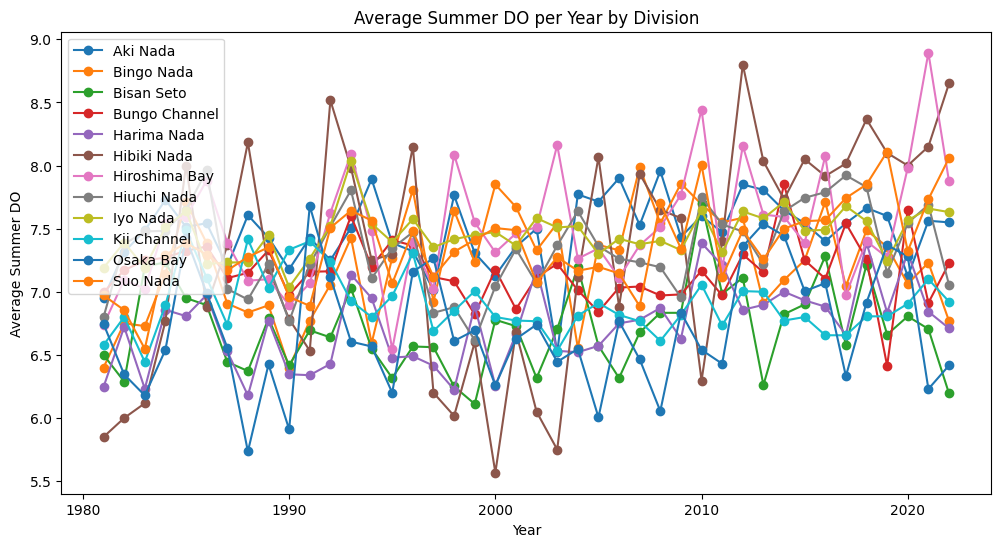

In [18]:
# Plot average DO per year for each division
plt.figure(figsize=(12, 6))

for division in summer_avg_do['division'].unique():
    div_data = summer_avg_do[summer_avg_do['division'] == division]
    plt.plot(div_data['year'], div_data['do_'], marker='o', label=division)

plt.xlabel('Year')
plt.ylabel('Average Summer DO')
plt.title('Average Summer DO per Year by Division')
plt.legend()

It seems that the data are misaligned. There are some variations in the sampling months of the water quality sample collection time. So let's make a new collumn for "season"

Successfully created the 'season' column. Here's a preview:
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay

Total data points per season:
season
Summer    10514
Winter    10464
Autumn    10194
Spring    10174
Name: count, dtype: int64


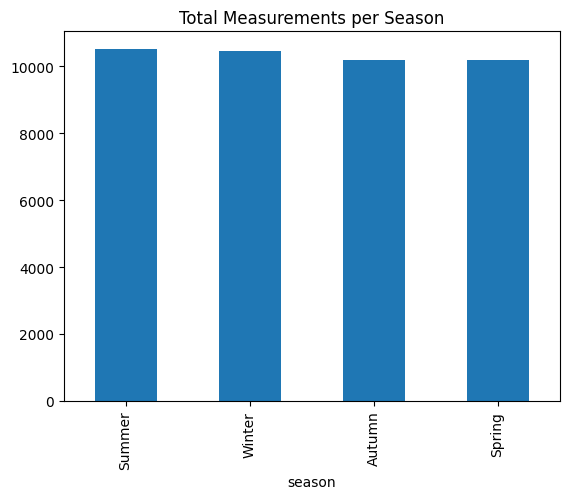

In [19]:
import pandas as pd

# This script assumes your 'merged_gdf' DataFrame is already loaded and prepared.

# --- 1. Define a function to determine the season from a month ---
def get_season(month):
    """Takes a month (integer 1-12) and returns the corresponding season."""
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8, 9]:
        return 'Summer'
    elif month in [10, 11]:
        return 'Autumn'
    else:
        return 'Unknown'

# --- 2. Apply this function to the 'surveymont' column to create the new 'season' column ---
merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season)

# --- 3. Verify the result ---
print("Successfully created the 'season' column. Here's a preview:")
# Display columns to see the mapping in action
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head())

print("\nTotal data points per season:")
print(merged_gdf['season'].value_counts())

# Visualize the season counts
merged_gdf['season'].value_counts().plot(kind='bar', title='Total Measurements per Season')
plt.show()

In [15]:
# First, filter the DataFrame to get only summer measurements
summer_gdf = merged_gdf[merged_gdf['season'] == 'Summer']

# Now, group by the water mass division and year, and calculate the mean DO
# IMPORTANT: Replace 'DO_column_name' with the actual name of the DO column in your data

summer_gdf['do_'] = pd.to_numeric(summer_gdf['do_'], errors='coerce')
summer_do_avg = summer_gdf.groupby(['division', 'year'])['do_'].mean()
print("\nAverage Summer DO for each Division and Year:")
print(summer_do_avg.head(10))



Average Summer DO for each Division and Year:
division  year
Aki Nada  1981    6.950000
          1982    7.314286
          1983    7.485714
          1984    7.728571
          1985    7.514286
          1986    7.542857
          1987    7.200000
          1988    7.607143
          1989    7.428571
          1990    7.178571
Name: do_, dtype: float64


c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\.venv\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [16]:
# Filter summer data for bottom layer measurements only

bottom_summer_gdf = summer_gdf[summer_gdf['saisuipoin'] == 2]
print(f"Original summer data points: {len(summer_gdf)}")
print(f"Filtered bottom layer summer points: {len(bottom_summer_gdf)}")
bottom_summer_gdf['do_'] = pd.to_numeric(bottom_summer_gdf['do_'], errors='coerce')
bottom_summer_do_avg = bottom_summer_gdf.groupby(['division', 'year'], as_index=False)['do_'].mean()

print("\nAverage Summer DO for the BOTTOM LAYER in each Division and Year:")
print(bottom_summer_do_avg.head(10))

import numpy as np

# 1. Calculate the overall average DO for each year
overall_avg_do = bottom_summer_do_avg.groupby('year')['do_'].mean()

# 2. Perform linear regression to find the best-fit line
#    np.polyfit() returns the slope (m) and intercept (b)
m, b = np.polyfit(overall_avg_do.index, overall_avg_do.values, 1)

# 3. Create the y-values for the trend line using the slope and intercept
trend_line = m * overall_avg_do.index + b

Original summer data points: 10514
Filtered bottom layer summer points: 5257

Average Summer DO for the BOTTOM LAYER in each Division and Year:
   division  year       do_
0  Aki Nada  1981  6.800000
1  Aki Nada  1982  7.242857
2  Aki Nada  1983  7.371429
3  Aki Nada  1984  7.628571
4  Aki Nada  1985  7.428571
5  Aki Nada  1986  7.314286
6  Aki Nada  1987  6.928571
7  Aki Nada  1988  7.385714
8  Aki Nada  1989  7.285714
9  Aki Nada  1990  6.971429


c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\.venv\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


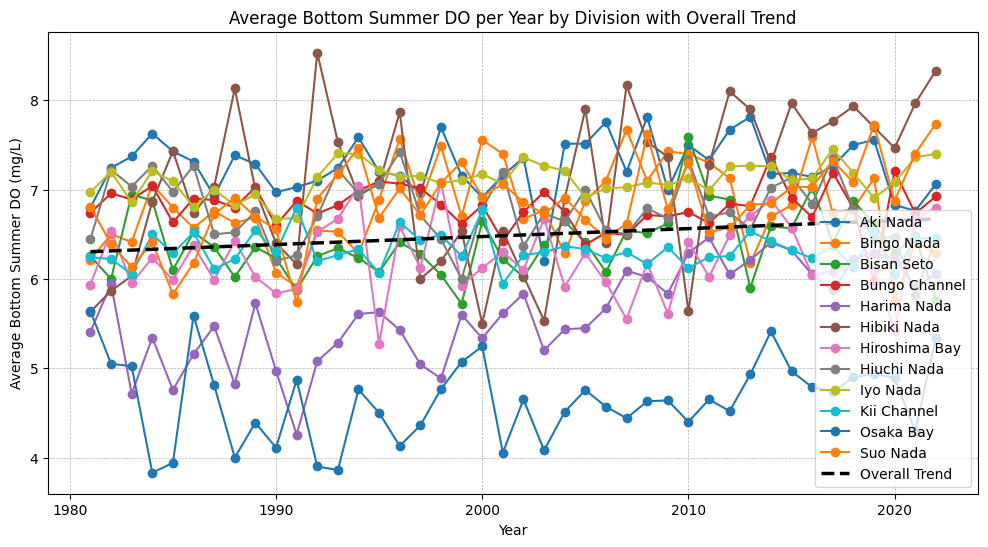

In [17]:
# Plot average DO per year for each division
plt.figure(figsize=(12, 6))

for division in bottom_summer_do_avg['division'].unique():
    div_data = bottom_summer_do_avg[bottom_summer_do_avg['division'] == division]
    plt.plot(div_data['year'], div_data['do_'], marker='o', label=division)

plt.xlabel('Year')
plt.ylabel('Average Bottom Summer DO')
plt.title('Average Bottom Summer DO per Year by Division')
plt.legend()

plt.plot(
    overall_avg_do.index,
    trend_line,
    color='black',
    linestyle='--',
    linewidth=2.5,
    label='Overall Trend'
)

plt.xlabel('Year')
plt.ylabel('Average Bottom Summer DO (mg/L)')
plt.title('Average Bottom Summer DO per Year by Division with Overall Trend')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

Nice. Now let's plot the yearly DO level on the SIS map.

In [ ]:
import pandas as pd
import numpy as np

# This script assumes 'merged_gdf' is in your notebook's memory.

# Ensure the 'do_' column is numeric, converting any non-numeric values to NaN (Not a Number)
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce')

# check do column data type
print(merged_gdf['do_'].dtype)

# Filter for the 'Summer' season, which we defined earlier
summer_gdf = merged_gdf[merged_gdf['season'] == 'Summer'].copy()

# Filter for the bottom layer using the 'saisuipoin' code 3
bottom_summer_gdf = summer_gdf[summer_gdf['saisuipoin'] == 2].copy()

# Drop any rows that do not have a valid DO measurement
bottom_summer_gdf.dropna(subset=['do_'], inplace=True)

print(f"Prepared {len(bottom_summer_gdf)} data points for summer bottom layer analysis.")

float64


In [24]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os

# --- Setup for the Loop ---

# Create a directory to save the output images
output_dir = '../reports/figures/yearly_do_maps'
os.makedirs(output_dir, exist_ok=True)

# Find the min and max DO values from the entire dataset to create a consistent color scale
vmin = bottom_summer_gdf['do_'].min()
vmax = bottom_summer_gdf['do_'].max()

# Get a sorted list of unique years to iterate through
years = sorted(bottom_summer_gdf['year'].unique())


# --- Loop to Create a Plot for Each Year ---

for year in years:
    # Filter the data for the current year in the loop
    year_data = bottom_summer_gdf[bottom_summer_gdf['year'] == year]
    
    if year_data.empty:
        print(f"No summer bottom DO data for {year}, skipping.")
        continue

    # --- Plotting ---
    fig = plt.figure(figsize=(12, 10))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

    # Add map features
    ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
    ax.add_feature(cfeature.OCEAN, zorder=0)
    ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

    # Create the scatter plot, coloring points by the 'do_' value
    scatter = ax.scatter(
        year_data.geometry.x,
        year_data.geometry.y,
        c=year_data['do_'],        # Color points based on this column
        cmap='jet_r',              # Colormap ('_r' reverses it, so red is low DO)
        vmin=vmin, vmax=vmax,      # Set consistent color limits
        transform=ccrs.PlateCarree(),
        s=30,                      # Point size
        zorder=2
    )
    
    # Add a colorbar
    cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.04, pad=0.05)
    cbar.set_label('Dissolved Oxygen (DO mg/L)')

    ax.set_title(f'Summer Bottom DO Distribution for {year}')
    
    # Save the figure
    output_path = os.path.join(output_dir, f'do_map_{year}.png')
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig) # Close the figure to free up memory
    
    print(f"Saved map for {year} to {output_path}")

print("\n✅ All yearly maps have been generated.")

Saved map for 1981 to ../reports/figures/yearly_do_maps\do_map_1981.png
Saved map for 1982 to ../reports/figures/yearly_do_maps\do_map_1982.png
Saved map for 1983 to ../reports/figures/yearly_do_maps\do_map_1983.png
Saved map for 1984 to ../reports/figures/yearly_do_maps\do_map_1984.png
Saved map for 1985 to ../reports/figures/yearly_do_maps\do_map_1985.png
Saved map for 1986 to ../reports/figures/yearly_do_maps\do_map_1986.png
Saved map for 1987 to ../reports/figures/yearly_do_maps\do_map_1987.png
Saved map for 1988 to ../reports/figures/yearly_do_maps\do_map_1988.png
Saved map for 1989 to ../reports/figures/yearly_do_maps\do_map_1989.png
Saved map for 1990 to ../reports/figures/yearly_do_maps\do_map_1990.png
Saved map for 1991 to ../reports/figures/yearly_do_maps\do_map_1991.png
Saved map for 1992 to ../reports/figures/yearly_do_maps\do_map_1992.png
Saved map for 1993 to ../reports/figures/yearly_do_maps\do_map_1993.png
Saved map for 1994 to ../reports/figures/yearly_do_maps\do_map_1